In [ ]:
# Experiment 9: Markov Model and Reinforcement Learning

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import random

np.random.seed(42)
random.seed(42)

Transition Probability Matrix:


,Sunny,Cloudy,Rainy
Sunny,0.7,0.2,0.1
Cloudy,0.3,0.4,0.3
Rainy,0.2,0.3,0.5


Row sums: [1. 1. 1.]


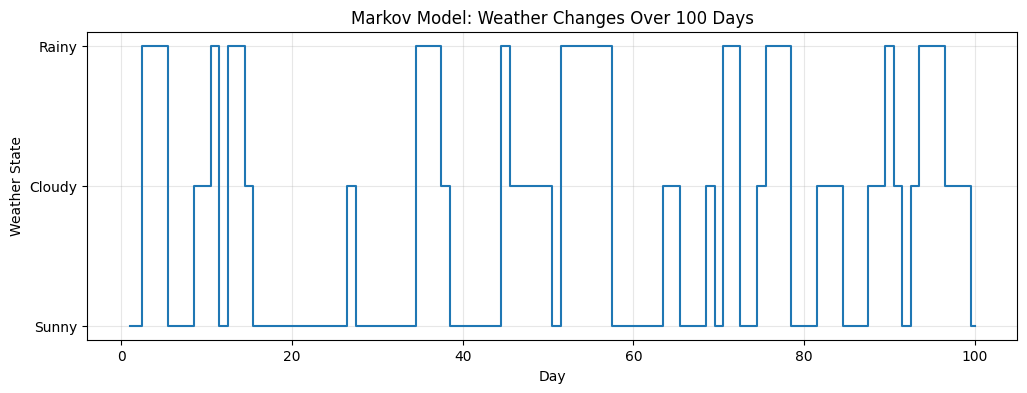

Observed state frequencies:
Sunny     51.0%
Cloudy    24.0%
Rainy     25.0%
Name: proportion, dtype: object


In [ ]:
# Exercise 1: Markov Model

states = ["Sunny", "Cloudy", "Rainy"]

# Rows = current state, columns = next state
transition_matrix = np.array([
    [0.70, 0.20, 0.10],  # Sunny
    [0.30, 0.40, 0.30],  # Cloudy
    [0.20, 0.30, 0.50]   # Rainy
])

transition_df = pd.DataFrame(
    transition_matrix,
    index=states,
    columns=states
)

print("Transition Probability Matrix:")
display(transition_df)

print("Row sums:", transition_matrix.sum(axis=1))

# Simulate weather for 100 days
np.random.seed(42)

current_state = 0  # Start with Sunny
weather_history = [current_state]

for day in range(99):
    current_state = np.random.choice(
        len(states),
        p=transition_matrix[current_state]
    )
    weather_history.append(current_state)

weather_names = [states[s] for s in weather_history]

# Plot the weather states over time
plt.figure(figsize=(12, 4))
plt.step(range(1, 101), weather_history, where="mid")
plt.yticks(range(3), states)
plt.xlabel("Day")
plt.ylabel("Weather State")
plt.title("Markov Model: Weather Changes Over 100 Days")
plt.grid(alpha=0.3)
plt.show()

# Estimate the long-run state frequencies
frequencies = pd.Series(weather_names).value_counts(normalize=True)
frequencies = frequencies.reindex(states, fill_value=0)

print("Observed state frequencies:")
print((frequencies * 100).round(2).astype(str) + "%")


In [ ]:
# Environment setup for Exercises 2-6

GRID_SIZE = 4
START = (0, 0)
GOAL = (3, 3)

ACTIONS = ["Up", "Down", "Left", "Right"]
MOVES = [(-1, 0), (1, 0), (0, -1), (0, 1)]


def state_to_position(state):
    return divmod(state, GRID_SIZE)


def position_to_state(position):
    return position[0] * GRID_SIZE + position[1]


def environment_step(state, action, goal_reward=10, step_reward=-1):
    row, col = state_to_position(state)
    dr, dc = MOVES[action]

    new_row = row + dr
    new_col = col + dc

    # Penalty for trying to leave the grid
    if not (0 <= new_row < GRID_SIZE and
            0 <= new_col < GRID_SIZE):
        return state, -2, False

    next_state = position_to_state((new_row, new_col))

    if (new_row, new_col) == GOAL:
        return next_state, goal_reward, True

    return next_state, step_reward, False


# Display the possible actions and their meanings
print("Available Actions:", ACTIONS)
print("Start State:", START)
print("Goal State:", GOAL)
print("Reward for reaching the goal: +10")
print("Reward for a normal step: -1")
print("Penalty for attempting to leave the grid: -2")


Available Actions: ['Up', 'Down', 'Left', 'Right']
Start State: (0, 0)
Goal State: (3, 3)
Reward for reaching the goal: +10
Reward for a normal step: -1
Penalty for attempting to leave the grid: -2


In [ ]:

# Q-learning helper function

def train_q_learning(
    episodes=600,
    alpha=0.1,
    gamma=0.95,
    epsilon=0.1,
    goal_reward=10,
    step_reward=-1,
    seed=42
):
    rng = np.random.default_rng(seed)

    n_states = GRID_SIZE * GRID_SIZE
    n_actions = len(ACTIONS)

    Q = np.zeros((n_states, n_actions))
    episode_rewards = []
    episode_steps = []
    episode_success = []

    start_state = position_to_state(START)
    goal_state = position_to_state(GOAL)

    for episode in range(episodes):
        state = start_state
        total_reward = 0
        steps = 0
        done = False

        while not done and steps < 100:
            # Epsilon-greedy action selection
            if rng.random() < epsilon:
                action = rng.integers(n_actions)
            else:
                best_actions = np.flatnonzero(
                    Q[state] == Q[state].max()
                )
                action = rng.choice(best_actions)

            next_state, reward, done = environment_step(
                state,
                action,
                goal_reward,
                step_reward
            )

            # Q-learning update
            if done:
                target = reward
            else:
                target = reward + gamma * np.max(Q[next_state])

            Q[state, action] += alpha * (
                target - Q[state, action]
            )

            state = next_state
            total_reward += reward
            steps += 1

        episode_rewards.append(total_reward)
        episode_steps.append(steps)
        episode_success.append(state == goal_state)

    return Q, episode_rewards, episode_steps, episode_success


# Compare two reward settings
Q_standard, rewards_standard, _, success_standard = train_q_learning(
    step_reward=-1,
    goal_reward=10,
    seed=42
)

Q_positive, rewards_positive, _, success_positive = train_q_learning(
    step_reward=0.2,
    goal_reward=10,
    seed=42
)

print("Standard reward setting: step = -1, goal = +10")
print("Success rate:",
      round(np.mean(success_standard) * 100, 2), "%")

print("\nModified reward setting: step = +0.2, goal = +10")
print("Success rate:",
      round(np.mean(success_positive) * 100, 2), "%")


Standard reward setting: step = -1, goal = +10
Success rate: 100.0 %

Modified reward setting: step = +0.2, goal = +10
Success rate: 95.33 %


Training completed!
Final 100-episode success rate: 100.0 %
Average steps in final 100 episodes: 6.51


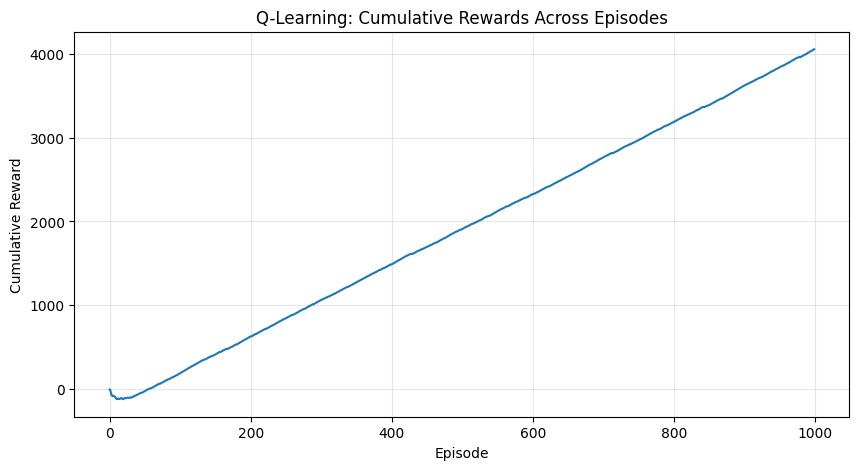

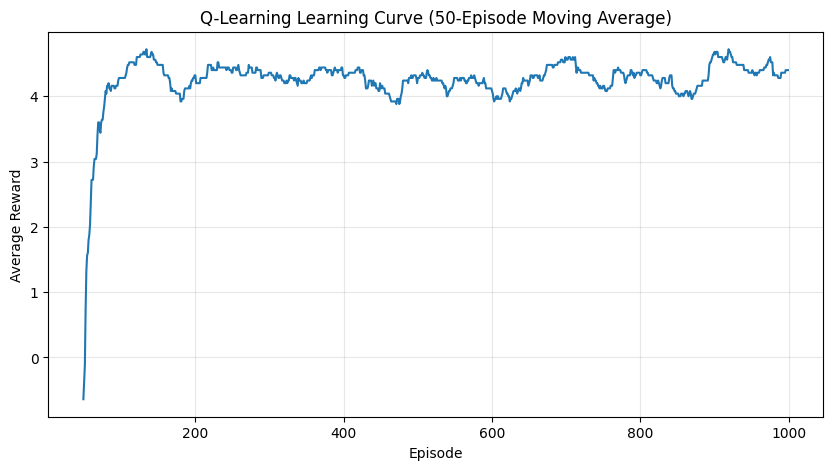

In [ ]:

# Exercise 3: Train the Q-learning agent

Q, episode_rewards, episode_steps, episode_success = train_q_learning(
    episodes=1000,
    alpha=0.1,
    gamma=0.95,
    epsilon=0.1,
    goal_reward=10,
    step_reward=-1,
    seed=42
)

print("Training completed!")
print("Final 100-episode success rate:",
      round(np.mean(episode_success[-100:]) * 100, 2), "%")
print("Average steps in final 100 episodes:",
      round(np.mean(episode_steps[-100:]), 2))

# Plot cumulative rewards across training episodes
cumulative_rewards = np.cumsum(episode_rewards)

plt.figure(figsize=(10, 5))
plt.plot(cumulative_rewards)
plt.xlabel("Episode")
plt.ylabel("Cumulative Reward")
plt.title("Q-Learning: Cumulative Rewards Across Episodes")
plt.grid(alpha=0.3)
plt.show()

# Plot a smoothed learning curve
window = 50
moving_average = pd.Series(episode_rewards).rolling(
    window=window
).mean()

plt.figure(figsize=(10, 5))
plt.plot(moving_average)
plt.xlabel("Episode")
plt.ylabel("Average Reward")
plt.title("Q-Learning Learning Curve (50-Episode Moving Average)")
plt.grid(alpha=0.3)
plt.show()


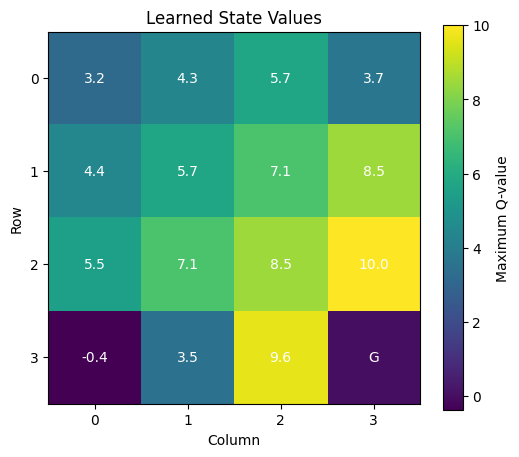

In [ ]:

# Visualize maximum Q-value for every state

max_q_values = Q.max(axis=1).reshape(GRID_SIZE, GRID_SIZE)

plt.figure(figsize=(6, 5))
plt.imshow(max_q_values, cmap="viridis")
plt.colorbar(label="Maximum Q-value")

for row in range(GRID_SIZE):
    for col in range(GRID_SIZE):
        state = position_to_state((row, col))
        label = "G" if (row, col) == GOAL else f"{max_q_values[row, col]:.1f}"
        plt.text(col, row, label, ha="center", va="center", color="white")

plt.xticks(range(GRID_SIZE))
plt.yticks(range(GRID_SIZE))
plt.title("Learned State Values")
plt.xlabel("Column")
plt.ylabel("Row")
plt.show()


In [ ]:

# Display the learned policy using arrows

ARROWS = ["↑", "↓", "←", "→"]

def show_policy(Q):
    policy = np.empty((GRID_SIZE, GRID_SIZE), dtype=object)

    for row in range(GRID_SIZE):
        for col in range(GRID_SIZE):
            if (row, col) == GOAL:
                policy[row, col] = "G"
            else:
                state = position_to_state((row, col))
                best_action = np.argmax(Q[state])
                policy[row, col] = ARROWS[best_action]

    print("Learned Policy:")
    print(pd.DataFrame(policy))


show_policy(Q)


Learned Policy:
   0  1  2  3
0  ↓  →  ↓  ↓
1  →  →  ↓  ↓
2  →  →  →  ↓
3  →  →  →  G


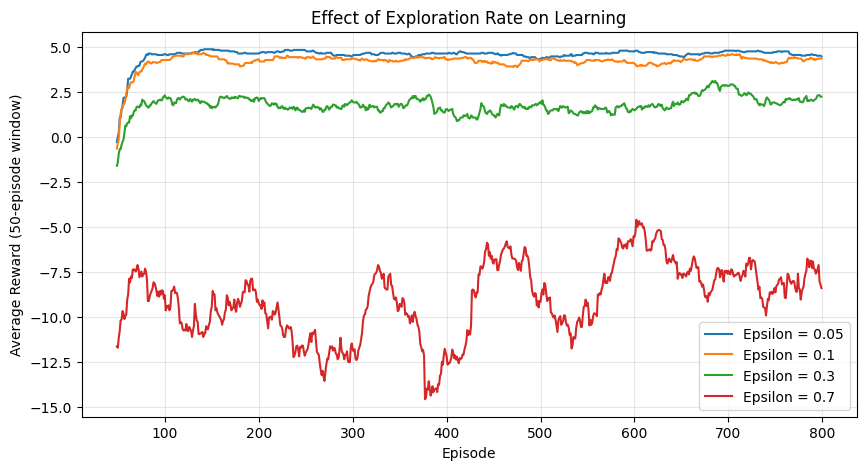

Final success rates:
Epsilon 0.05: 100.00%
Epsilon 0.1: 100.00%
Epsilon 0.3: 100.00%
Epsilon 0.7: 100.00%


In [ ]:

# Exercise 4: Compare epsilon values

epsilon_values = [0.05, 0.1, 0.3, 0.7]
epsilon_results = {}

for eps in epsilon_values:
    result = train_q_learning(
        episodes=800,
        alpha=0.1,
        gamma=0.95,
        epsilon=eps,
        seed=42
    )

    epsilon_results[eps] = {
        "Q": result[0],
        "Rewards": result[1],
        "Steps": result[2],
        "Success": result[3]
    }

plt.figure(figsize=(10, 5))

for eps in epsilon_values:
    rewards = epsilon_results[eps]["Rewards"]
    smooth = pd.Series(rewards).rolling(50).mean()
    plt.plot(smooth, label=f"Epsilon = {eps}")

plt.xlabel("Episode")
plt.ylabel("Average Reward (50-episode window)")
plt.title("Effect of Exploration Rate on Learning")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print("Final success rates:")
for eps in epsilon_values:
    success = epsilon_results[eps]["Success"][-100:]
    print(f"Epsilon {eps}: {np.mean(success) * 100:.2f}%")


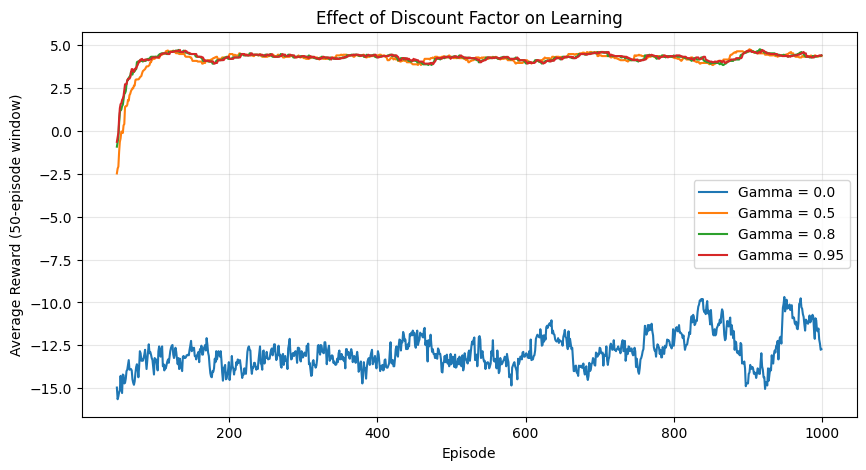


Learned policy for gamma = 0.0
Learned Policy:
   0  1  2  3
0  ↓  ↓  ↓  ↓
1  ↑  ↑  ↑  ↑
2  ↑  ↑  ↑  ↓
3  ↑  ↑  →  G

Learned policy for gamma = 0.5
Learned Policy:
   0  1  2  3
0  ↓  ↓  ↓  ↓
1  →  ↓  ↓  ↓
2  →  →  →  ↓
3  →  →  →  G

Learned policy for gamma = 0.8
Learned Policy:
   0  1  2  3
0  ↓  ↓  ↓  ↓
1  →  ↓  ↓  ↓
2  →  →  →  ↓
3  →  →  →  G

Learned policy for gamma = 0.95
Learned Policy:
   0  1  2  3
0  ↓  →  ↓  ↓
1  →  →  ↓  ↓
2  →  →  →  ↓
3  →  →  →  G


In [ ]:

# Exercise 5: Compare discount factors

gamma_values = [0.0, 0.5, 0.8, 0.95]
gamma_results = {}

for gamma_value in gamma_values:
    result = train_q_learning(
        episodes=1000,
        alpha=0.1,
        gamma=gamma_value,
        epsilon=0.1,
        goal_reward=10,
        step_reward=-1,
        seed=42
    )

    gamma_results[gamma_value] = {
        "Q": result[0],
        "Rewards": result[1],
        "Steps": result[2],
        "Success": result[3]
    }

plt.figure(figsize=(10, 5))

for gamma_value in gamma_values:
    rewards = gamma_results[gamma_value]["Rewards"]
    smooth = pd.Series(rewards).rolling(50).mean()
    plt.plot(smooth, label=f"Gamma = {gamma_value}")

plt.xlabel("Episode")
plt.ylabel("Average Reward (50-episode window)")
plt.title("Effect of Discount Factor on Learning")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# Display learned policies for each discount factor
for gamma_value in gamma_values:
    print(f"\nLearned policy for gamma = {gamma_value}")
    show_policy(gamma_results[gamma_value]["Q"])


In [ ]:

# Exercise 6: Evaluate a learned policy

def evaluate_policy(Q, episodes=200, seed=123):
    rng = np.random.default_rng(seed)

    rewards_list = []
    steps_list = []
    successes = []

    start_state = position_to_state(START)
    goal_state = position_to_state(GOAL)

    for episode in range(episodes):
        state = start_state
        total_reward = 0
        steps = 0
        done = False

        while not done and steps < 100:
            # Greedy action: no random exploration during evaluation
            best_actions = np.flatnonzero(
                Q[state] == Q[state].max()
            )
            action = rng.choice(best_actions)

            next_state, reward, done = environment_step(
                state, action, goal_reward=10, step_reward=-1
            )

            total_reward += reward
            steps += 1
            state = next_state

        rewards_list.append(total_reward)
        steps_list.append(steps)
        successes.append(state == goal_state)

    return {
        "Average Reward": np.mean(rewards_list),
        "Average Steps": np.mean(steps_list),
        "Success Rate (%)": np.mean(successes) * 100
    }


# Compare different epsilon settings using greedy evaluation
evaluation_rows = []

for eps in epsilon_values:
    metrics = evaluate_policy(
        epsilon_results[eps]["Q"],
        episodes=200,
        seed=123
    )

    evaluation_rows.append({
        "Setting": f"Epsilon {eps}",
        **metrics
    })

# Compare different discount factor settings
for gamma_value in gamma_values:
    metrics = evaluate_policy(
        gamma_results[gamma_value]["Q"],
        episodes=200,
        seed=123
    )

    evaluation_rows.append({
        "Setting": f"Gamma {gamma_value}",
        **metrics
    })

evaluation_df = pd.DataFrame(evaluation_rows)

print("Policy Evaluation Results:")
display(evaluation_df.round(2))


Policy Evaluation Results:


,Setting,Average Reward,Average Steps,Success Rate (%)
0,Epsilon 0.05,5.00,6.00,100.0
1,Epsilon 0.1,5.00,6.00,100.0
2,Epsilon 0.3,5.00,6.00,100.0
3,Epsilon 0.7,5.00,6.00,100.0
4,Gamma 0.0,-27.06,37.23,92.5
5,Gamma 0.5,5.00,6.00,100.0
6,Gamma 0.8,5.00,6.00,100.0
7,Gamma 0.95,5.00,6.00,100.0


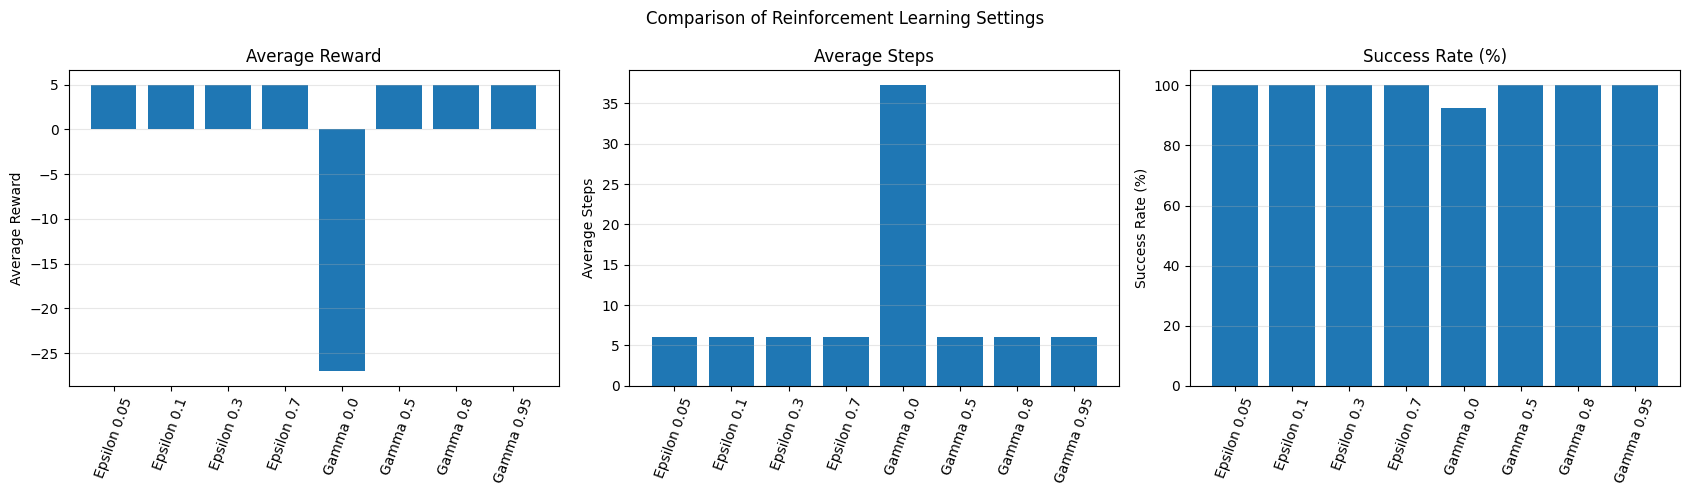

In [ ]:

# Plot evaluation metrics

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

metrics_to_plot = [
    ("Average Reward", "Average Reward"),
    ("Average Steps", "Average Steps"),
    ("Success Rate (%)", "Success Rate (%)")
]

for ax, (column, title) in zip(axes, metrics_to_plot):
    ax.bar(evaluation_df["Setting"], evaluation_df[column])
    ax.set_title(title)
    ax.set_ylabel(title)
    ax.tick_params(axis="x", rotation=70)
    ax.grid(axis="y", alpha=0.3)

plt.suptitle("Comparison of Reinforcement Learning Settings")
plt.tight_layout()
plt.show()
